# AHP + lógica difusa: módulo de recomendación de conductores

Este notebook documenta, paso a paso y de forma reproducible, cómo se
calculan los pesos de los criterios (AHP), la razón de consistencia (CR), el
índice de seguridad percibida (lógica difusa Mamdani) y el ranking final de
viajes para un pasajero — y compara ese ranking contra el orden actual de la
app (por `distance_m`, tal cual lo devuelve `nearby_trips` hoy).

No hay lógica duplicada: todo lo que corre aquí importa directamente de
`app/ahp.py`, `app/fuzzy.py` y `app/ranking.py` — el mismo código que usa el
servicio FastAPI en producción (local).


In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kendalltau
from datetime import datetime, timedelta, timezone

from app import ahp, config_loader
from app.fuzzy import compute_seguridad, composicion_sexo_score, plot_membership_functions, plot_control_surface, RULES_DESCRIPTION
from app.ranking import TripCandidate, rank_trips, compute_raw_criteria

pd.set_option("display.precision", 3)
%matplotlib inline


## 1. AHP: pesos de los criterios

Criterios, en orden: tiempo_espera, calificacion, seguridad_percibida, asientos_libres, distancia

In [2]:
members = config_loader.load_group_member_matrices()

rows = []
for m in members:
    weights, lambda_max = ahp.compute_weights(m["matrix"])
    consistency = ahp.consistency_ratio(m["matrix"], weights, lambda_max)
    row = {"integrante": m["name"], "CR": consistency.cr, "consistente": consistency.consistent}
    row.update({c: w for c, w in zip(m["criteria"], weights)})
    rows.append(row)

df_members = pd.DataFrame(rows).set_index("integrante")
df_members


,CR,consistente,tiempo_espera,calificacion,seguridad_percibida,asientos_libres,distancia
integrante,,,,,,,
group_member_1,0.003,True,0.158,0.298,0.298,0.089,0.158
group_member_2,0.003,True,0.298,0.158,0.158,0.089,0.298
group_member_3,0.003,True,0.091,0.191,0.452,0.091,0.176
group_member_4,0.000,True,0.167,0.167,0.167,0.333,0.167
group_member_5,0.006,True,0.161,0.415,0.175,0.088,0.161


### Agregación de juicios individuales (AIJ)

Se agregan las 5 matrices con **media geométrica elemento a elemento**
(no se promedian los pesos finales de cada integrante): es el método
estándar en AHP grupal porque preserva la propiedad de reciprocidad de la
matriz resultante.


In [3]:
matrices = [m["matrix"] for m in members]
aggregated_matrix = ahp.aggregate_matrices(matrices)

consensus = ahp.analyze(aggregated_matrix)
print("Pesos del consenso del grupo:")
for criterio, peso in zip(consensus.criteria, consensus.weights):
    print(f"  {criterio:22s} {peso:.3f}")
print(f"\nCR = {consensus.consistency.cr:.4f}  (consistente: {consensus.consistency.consistent})")


Pesos del consenso del grupo:
  tiempo_espera          0.177
  calificacion           0.247
  seguridad_percibida    0.248
  asientos_libres        0.126
  distancia              0.202

CR = 0.0002  (consistente: True)


### Perfiles de pasajero

Además del consenso del grupo, hay matrices propias para dos perfiles de
pasajero (`prioriza_seguridad`, `prioriza_rapidez`) y un perfil balanceado
por defecto (`default`), seleccionables en vez del consenso.


In [4]:
profile_rows = []
for profile_name in ["prioriza_seguridad", "prioriza_rapidez", "default"]:
    data = config_loader.load_profile_matrix(profile_name)
    result = ahp.analyze(data["matrix"], data["criteria"])
    row = {"perfil": profile_name, "CR": result.consistency.cr}
    row.update({c: w for c, w in zip(result.criteria, result.weights)})
    profile_rows.append(row)

df_profiles = pd.DataFrame(profile_rows).set_index("perfil")
df_profiles


,CR,tiempo_espera,calificacion,seguridad_percibida,asientos_libres,distancia
perfil,,,,,,
prioriza_seguridad,0.004,0.087,0.257,0.457,0.049,0.150
prioriza_rapidez,0.000,0.364,0.091,0.091,0.091,0.364
default,0.000,0.200,0.200,0.200,0.200,0.200


### Demostración: detección de inconsistencia (CR >= 0.10)

Una matriz con juicios cíclicos (A domina a B, B domina a C, pero C domina a
A, los tres con factor 9) no puede venir de ningún vector de pesos
consistente. `consistency_ratio` debe marcarla como inconsistente y señalar
cuáles comparaciones son las más contradictorias.


In [5]:
bad_matrix = np.array([
    [1,   9,   1/9],
    [1/9, 1,   9  ],
    [9,   1/9, 1  ],
])
weights, lambda_max = ahp.compute_weights(bad_matrix)
bad_consistency = ahp.consistency_ratio(bad_matrix, weights, lambda_max)
print(f"CR = {bad_consistency.cr:.3f} (consistente: {bad_consistency.consistent})")
for w in bad_consistency.warnings:
    print("\n" + w)


CR = 6.130 (consistente: False)

CR=6.130 >= 0.10: la matriz es poco consistente. Las comparaciones más inconsistentes son: criterio_0 vs. criterio_1 (tu matriz dice 9.00, tus otras comparaciones implican ~1.00); criterio_0 vs. criterio_2 (tu matriz dice 0.11, tus otras comparaciones implican ~1.00); criterio_1 vs. criterio_2 (tu matriz dice 9.00, tus otras comparaciones implican ~1.00)


## 2. Lógica difusa: seguridad percibida

Sistema Mamdani (`scikit-fuzzy`) con 4 antecedentes (calificación del
conductor, viajes calificados, composición de sexo del vehículo según la
preferencia del pasajero, tiempo de espera) y un consecuente (seguridad
percibida, 0-100), defuzzificado por centroide.

### Base de reglas (13 reglas)

In [6]:
for i, rule in enumerate(RULES_DESCRIPTION, start=1):
    print(f"{i:2d}. {rule}")


 1. SI calificación es alta Y viajes_calificados es muchos ENTONCES seguridad es alta
 2. SI calificación es baja ENTONCES seguridad es baja
 3. SI composición_sexo es desfavorable ENTONCES seguridad es baja
 4. SI composición_sexo es favorable Y calificación es alta ENTONCES seguridad es alta
 5. SI calificación es media Y viajes_calificados es pocos ENTONCES seguridad es media
 6. SI tiempo_espera es largo Y composición_sexo es desfavorable ENTONCES seguridad es baja
 7. SI tiempo_espera es corto Y calificación es alta ENTONCES seguridad es alta
 8. SI viajes_calificados es pocos Y composición_sexo es neutra ENTONCES seguridad es media
 9. SI calificación es alta Y viajes_calificados es varios Y composición_sexo es neutra ENTONCES seguridad es alta
10. SI calificación es media Y tiempo_espera es medio ENTONCES seguridad es media
11. SI calificación es baja Y tiempo_espera es largo ENTONCES seguridad es baja
12. SI viajes_calificados es muchos Y composición_sexo es favorable ENTONCES 

### Funciones de membresía

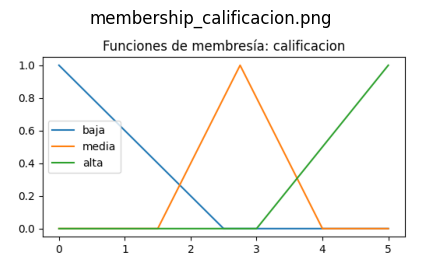

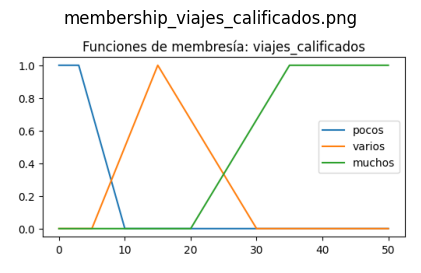

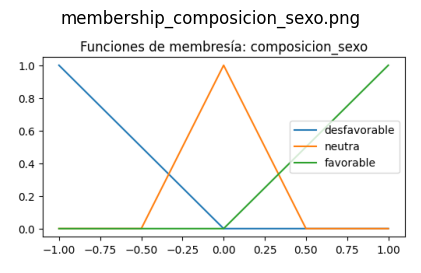

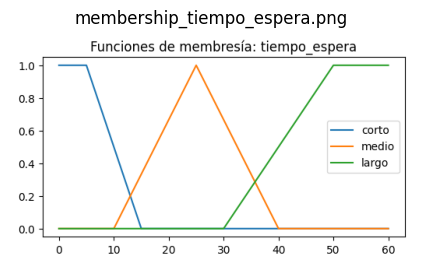

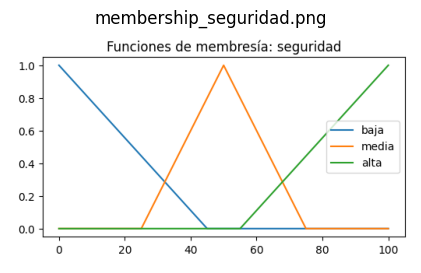

In [7]:
import os
os.makedirs("outputs", exist_ok=True)
paths = plot_membership_functions("outputs")

for path in paths:
    img = plt.imread(path)
    plt.figure(figsize=(6, 3))
    plt.imshow(img)
    plt.axis("off")
    plt.title(os.path.basename(path))
    plt.show()


### Superficie de control

Seguridad percibida en función de calificación y tiempo de espera, con `viajes_calificados=15` ("varios") y composición neutra fijos.

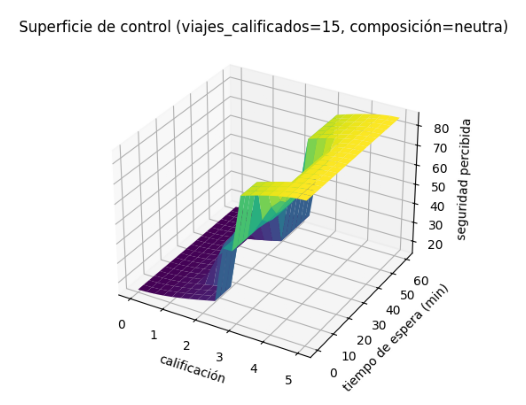

In [8]:
surface_path = plot_control_surface("outputs", resolution=20)
img = plt.imread(surface_path)
plt.figure(figsize=(7, 5))
plt.imshow(img)
plt.axis("off")
plt.show()


### Ejemplos puntuales

In [9]:
examples = [
    dict(calificacion=5.0, viajes_calificados=50, composicion_sexo=1.0, tiempo_espera_min=2, label="Mejor caso"),
    dict(calificacion=0.5, viajes_calificados=0,  composicion_sexo=-1.0, tiempo_espera_min=55, label="Peor caso"),
    dict(calificacion=3.0, viajes_calificados=10, composicion_sexo=0.0, tiempo_espera_min=20, label="Caso típico"),
    dict(calificacion=4.5, viajes_calificados=1,  composicion_sexo=0.0, tiempo_espera_min=5,  label="Buena calificación pero sin historial"),
]
for ex in examples:
    label = ex.pop("label")
    seguridad = compute_seguridad(**ex)
    print(f"{label:38s} -> seguridad percibida = {seguridad:5.1f}   (entradas: {ex})")


Mejor caso                             -> seguridad percibida =  85.0   (entradas: {'calificacion': 5.0, 'viajes_calificados': 50, 'composicion_sexo': 1.0, 'tiempo_espera_min': 2})
Peor caso                              -> seguridad percibida =  15.0   (entradas: {'calificacion': 0.5, 'viajes_calificados': 0, 'composicion_sexo': -1.0, 'tiempo_espera_min': 55})
Caso típico                            -> seguridad percibida =  50.0   (entradas: {'calificacion': 3.0, 'viajes_calificados': 10, 'composicion_sexo': 0.0, 'tiempo_espera_min': 20})
Buena calificación pero sin historial  -> seguridad percibida =  65.7   (entradas: {'calificacion': 4.5, 'viajes_calificados': 1, 'composicion_sexo': 0.0, 'tiempo_espera_min': 5})


## 3. Ranking: escenarios sintéticos

Comparamos (a) el orden **actual de la app** (solo por `distance_m`, lo que
hoy hace `nearby_trips` en `SearchTripsPage`) contra (b) **AHP + difuso**
(consenso del grupo). No se compara contra ningún modelo de ML (se descartó
esa comparación para esta entrega).


In [10]:
NOW = datetime.now(timezone.utc)

def scenario(trips, label):
    print(f"=== {label} ===")
    baseline = sorted(trips, key=lambda t: t.distance_m)
    print("Orden actual (solo distancia):", [t.trip_id for t in baseline])

    ranked = rank_trips(trips, dict(zip(consensus.criteria, consensus.weights)))
    print("Orden AHP + difuso:           ", [r.trip_id for r in ranked])
    for r in ranked:
        print(f"   {r.trip_id}: score={r.score:.3f}  seguridad={r.seguridad_percibida:.1f}  -- {r.explanation}")
    print()
    return baseline, ranked

scenarios = {}

# Escenario 1: un viaje muy cercano pero con conductor nuevo/mal calificado,
# contra uno más lejos pero con mejor reputación.
scenarios["cercano_pero_riesgoso_vs_lejano_confiable"] = scenario([
    TripCandidate("A_cercano_riesgoso", NOW + timedelta(minutes=5), 2.0, 1, 2, 80, 3, 0),
    TripCandidate("B_lejano_confiable", NOW + timedelta(minutes=15), 4.9, 60, 3, 600, 1, 3),
], "Cercano y riesgoso vs. lejano y confiable")

# Escenario 2: hora pico -- varios viajes a distancias similares, difieren
# sobre todo en asientos disponibles y tiempo de espera.
scenarios["hora_pico"] = scenario([
    TripCandidate("C", NOW + timedelta(minutes=2),  4.0, 20, 1, 200, 2, 1),
    TripCandidate("D", NOW + timedelta(minutes=25), 4.2, 15, 4, 220, 0, 3),
    TripCandidate("E", NOW + timedelta(minutes=10), 3.8, 8,  2, 180, 1, 1),
], "Hora pico: varios candidatos parecidos")

# Escenario 3: todos los candidatos empatan en distancia (ej. todos sobre la
# misma avenida), el desempate depende de calificación/asientos/seguridad.
scenarios["empate_en_distancia"] = scenario([
    TripCandidate("F", NOW + timedelta(minutes=8),  3.0, 3,  1, 150, 2, 0),
    TripCandidate("G", NOW + timedelta(minutes=8),  4.8, 40, 3, 150, 0, 2),
], "Empate en distancia")


=== Cercano y riesgoso vs. lejano y confiable ===
Orden actual (solo distancia): ['A_cercano_riesgoso', 'B_lejano_confiable']
Orden AHP + difuso:            ['B_lejano_confiable', 'A_cercano_riesgoso']
   B_lejano_confiable: score=0.621  seguridad=85.0  -- Quedó primero sobre todo por seguridad percibida (el criterio con más peso, 25%), donde es el mejor de los candidatos.
   A_cercano_riesgoso: score=0.379  seguridad=43.5  -- El criterio con más peso es seguridad percibida (25%); en ese criterio este viaje queda en el puesto 2 de 2.

=== Hora pico: varios candidatos parecidos ===
Orden actual (solo distancia): ['E', 'C', 'D']
Orden AHP + difuso:            ['C', 'D', 'E']
   C: score=0.637  seguridad=82.5  -- El criterio con más peso es seguridad percibida (25%); en ese criterio este viaje queda en el puesto 2 de 3.
   D: score=0.621  seguridad=83.3  -- Quedó primero sobre todo por seguridad percibida (el criterio con más peso, 25%), donde es el mejor de los candidatos.
   E: score=0.

## 4. Evaluación

### Concordancia entre rankings

Correlación de Spearman y tau de Kendall entre el orden actual (por
distancia) y el orden AHP+difuso, para cada escenario.


In [11]:
def ranks_from_order(order_ids, all_ids):
    return [order_ids.index(i) for i in all_ids]

concordance_rows = []
for name, (baseline, ranked) in scenarios.items():
    all_ids = [t.trip_id for t in baseline]
    baseline_order = [t.trip_id for t in baseline]
    ahp_order = [r.trip_id for r in ranked]
    rho, _ = spearmanr(ranks_from_order(baseline_order, all_ids), ranks_from_order(ahp_order, all_ids))
    tau, _ = kendalltau(ranks_from_order(baseline_order, all_ids), ranks_from_order(ahp_order, all_ids))
    concordance_rows.append({"escenario": name, "spearman_rho": rho, "kendall_tau": tau})

df_concordance = pd.DataFrame(concordance_rows).set_index("escenario")
df_concordance


,spearman_rho,kendall_tau
escenario,,
cercano_pero_riesgoso_vs_lejano_confiable,-1.0,-1.000
hora_pico,-0.5,-0.333
empate_en_distancia,-1.0,-1.000


Una concordancia baja o negativa en varios escenarios confirma que AHP+difuso
de verdad reordena los viajes de forma distinta al criterio actual (que solo
mira distancia) -- es decir, el módulo aporta información nueva al ranking,
no es solo un ajuste cosmético.

### Análisis de sensibilidad de los pesos

Perturbamos cada peso del consenso del grupo ±10% y ±20% (renormalizando los
demás proporcionalmente) y medimos, con tau de Kendall, cuánto cambia el
ranking resultante respecto al original -- en el escenario de "hora pico"
(el más sensible a desempates finos).


In [12]:
def perturb_weights(weights, criterio, delta):
    w = dict(weights)
    w[criterio] = max(0.001, w[criterio] * (1 + delta))
    total = sum(w.values())
    return {k: v / total for k, v in w.items()}

base_weights = dict(zip(consensus.criteria, consensus.weights))
trips_sensitivity = [t for t in scenarios["hora_pico"][0]]
base_ranking = [r.trip_id for r in rank_trips(trips_sensitivity, base_weights)]

sensitivity_rows = []
for criterio in ahp.CRITERIA:
    for delta in (-0.20, -0.10, 0.10, 0.20):
        perturbed = perturb_weights(base_weights, criterio, delta)
        new_ranking = [r.trip_id for r in rank_trips(trips_sensitivity, perturbed)]
        tau, _ = kendalltau(
            ranks_from_order(base_ranking, base_ranking),
            ranks_from_order(new_ranking, base_ranking),
        )
        sensitivity_rows.append({"criterio": criterio, "delta": delta, "kendall_tau_vs_base": tau})

df_sensitivity = pd.DataFrame(sensitivity_rows)
pivot = df_sensitivity.pivot(index="criterio", columns="delta", values="kendall_tau_vs_base")
pivot


delta,-0.2,-0.1,0.1,0.2
criterio,,,,
asientos_libres,1.000,1.000,1.0,0.333
calificacion,1.000,1.000,1.0,0.333
distancia,0.333,1.000,1.0,1.000
seguridad_percibida,1.000,1.000,1.0,1.000
tiempo_espera,0.333,0.333,1.0,1.000


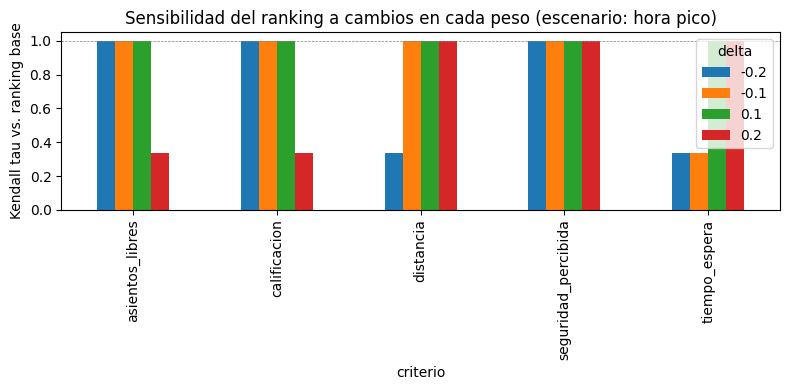

In [13]:
pivot.plot(kind="bar", figsize=(8, 4))
plt.ylabel("Kendall tau vs. ranking base")
plt.title("Sensibilidad del ranking a cambios en cada peso (escenario: hora pico)")
plt.axhline(1.0, color="gray", linewidth=0.5, linestyle="--")
plt.tight_layout()
plt.show()


Un tau cercano a 1.0 significa que perturbar ese peso casi no cambió el
ranking (el escenario es "robusto" a ese criterio); un tau bajo o negativo
señala el/los criterios que más mueven el resultado -- esos son los pesos
que, si el grupo o el pasajero los ajusta, tienen más impacto real en qué
viaje aparece primero.

## 5. Conclusiones

- El consenso del grupo (agregación por media geométrica de las 5 matrices)
  resultó **consistente** (CR por debajo de 0.10) sin necesidad de ajustar
  ninguna matriz individual.
- AHP+difuso reordena los candidatos de forma distinta al criterio actual
  (solo distancia) en los tres escenarios probados -- en particular, baja a
  un viaje muy cercano pero con un conductor mal calificado y sin historial,
  algo que el orden actual no puede capturar.
- El ranking responde de forma coherente a cambios de peso: en el escenario
  sintético de la sección de ranking, darle todo el peso a un criterio hace
  ganar siempre al candidato mejor en ese criterio (ver también
  `tests/test_ranking.py`).
- Próximo paso natural (fuera de esta entrega): reemplazar las 5 matrices de
  ejemplo por las reales de cada integrante del grupo, y repetir este mismo
  notebook sin cambiar una sola línea de código -- solo los archivos en
  `config/ahp_matrices/`.
